# The training stages in the proficient LDA frame

The proficient 1-camera embedding (`neuromodulators/1_proficient_1cam_ld1`: `syllable_data.SYLLABLES`,
shrinkage mouse-weighted LDA, fitted on proficient sessions only, signs aligned to the paper's 2-camera
LD1 / LD2), with Early, Late and Pre-rec sessions of the same mice **projected** into it.

What the projection separates:
- **Pre-rec** is a few days before recording, on the **same recording rig** but with the camera at **30 Hz**
  (Proficient: 60 Hz): its displacement from the same mice's proficient positions is mostly the **acquisition**
  (frame rate), plus a few days and the biased protocol;
- **Late** and **Early** (training rig, 30 Hz) add **learning** and a different rig on top.

So the question per stage: how far do mice move, in which directions, and do they keep their place on the
individuality axes? Code: `stage_projection.py`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import stage_projection as spj
import paper_style as ps

warnings.filterwarnings('ignore')
pd.set_option('display.width', 200)
ps.use('paper')
emb, sc = spj.frame()
P = spj.project_stages(emb)
SHARE = emb.axis_share
P.groupby('stage', sort=False).agg(sessions=('mouse_name', 'size'), mice=('mouse_name', 'nunique'))

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


,sessions,mice
stage,,
Early,35,35
Late,49,49
Pre-rec,93,37


In [2]:
#%%
""" HOW FAR, IN WHICH DIRECTIONS, AND DO MICE KEEP THEIR PLACE? (vs the same mice's proficient positions) """
T = spj.stage_table(sc, P)
print(f"typical proficient mouse distance from the centre: {T.attrs['typical']:.1f} LD units; "
      f"LD1-3 carry {SHARE[:3].sum():.0%} of the between-mouse variance; own-mouse chance {T.attrs['chance']:.3f}")
T.round(3)

typical proficient mouse distance from the centre: 12.1 LD units; LD1-3 carry 32% of the between-mouse variance; own-mouse chance 0.017


,mice,sessions,offset,offset_LD1-3,LD1 shift,LD2 shift,LD3 shift,r LD1,r LD2,r LD3,own_mouse
stage,,,,,,,,,,,
Early,35,35,13.489,0.138,-0.325,-0.702,-1.011,0.386,-0.005,0.200,0.029
Late,49,49,8.945,0.056,-0.162,0.184,-0.485,0.449,0.276,0.425,0.082
Pre-rec,37,93,4.822,0.027,-0.122,0.136,0.047,0.832,0.730,0.732,0.527


In [3]:
#%%
""" DO MICE KEEP THEIR LD1 PLACE? stage vs proficient LD1, mouse means: Spearman, 95% CI over mice, BH over the
three stages; lab-removed (ranks residualised on lab, within-lab permutation), as fig_time_horizon panel g """
RET = spj.ld1_retention(sc, P)
RET.round(4)

,n_mice,rho,p,lo,hi,rho_lab,p_lab,slope,q,q_lab
stage,,,,,,,,,,
Early,35,0.2249,0.1939,-0.1269,0.5350,0.2396,0.2172,0.1879,0.1939,0.2585
Late,49,0.3772,0.0075,0.0862,0.6123,0.1904,0.2585,0.3500,0.0113,0.2585
Pre-rec,37,0.8936,0.0000,0.7863,0.9377,0.8294,0.0001,0.7509,0.0000,0.0003


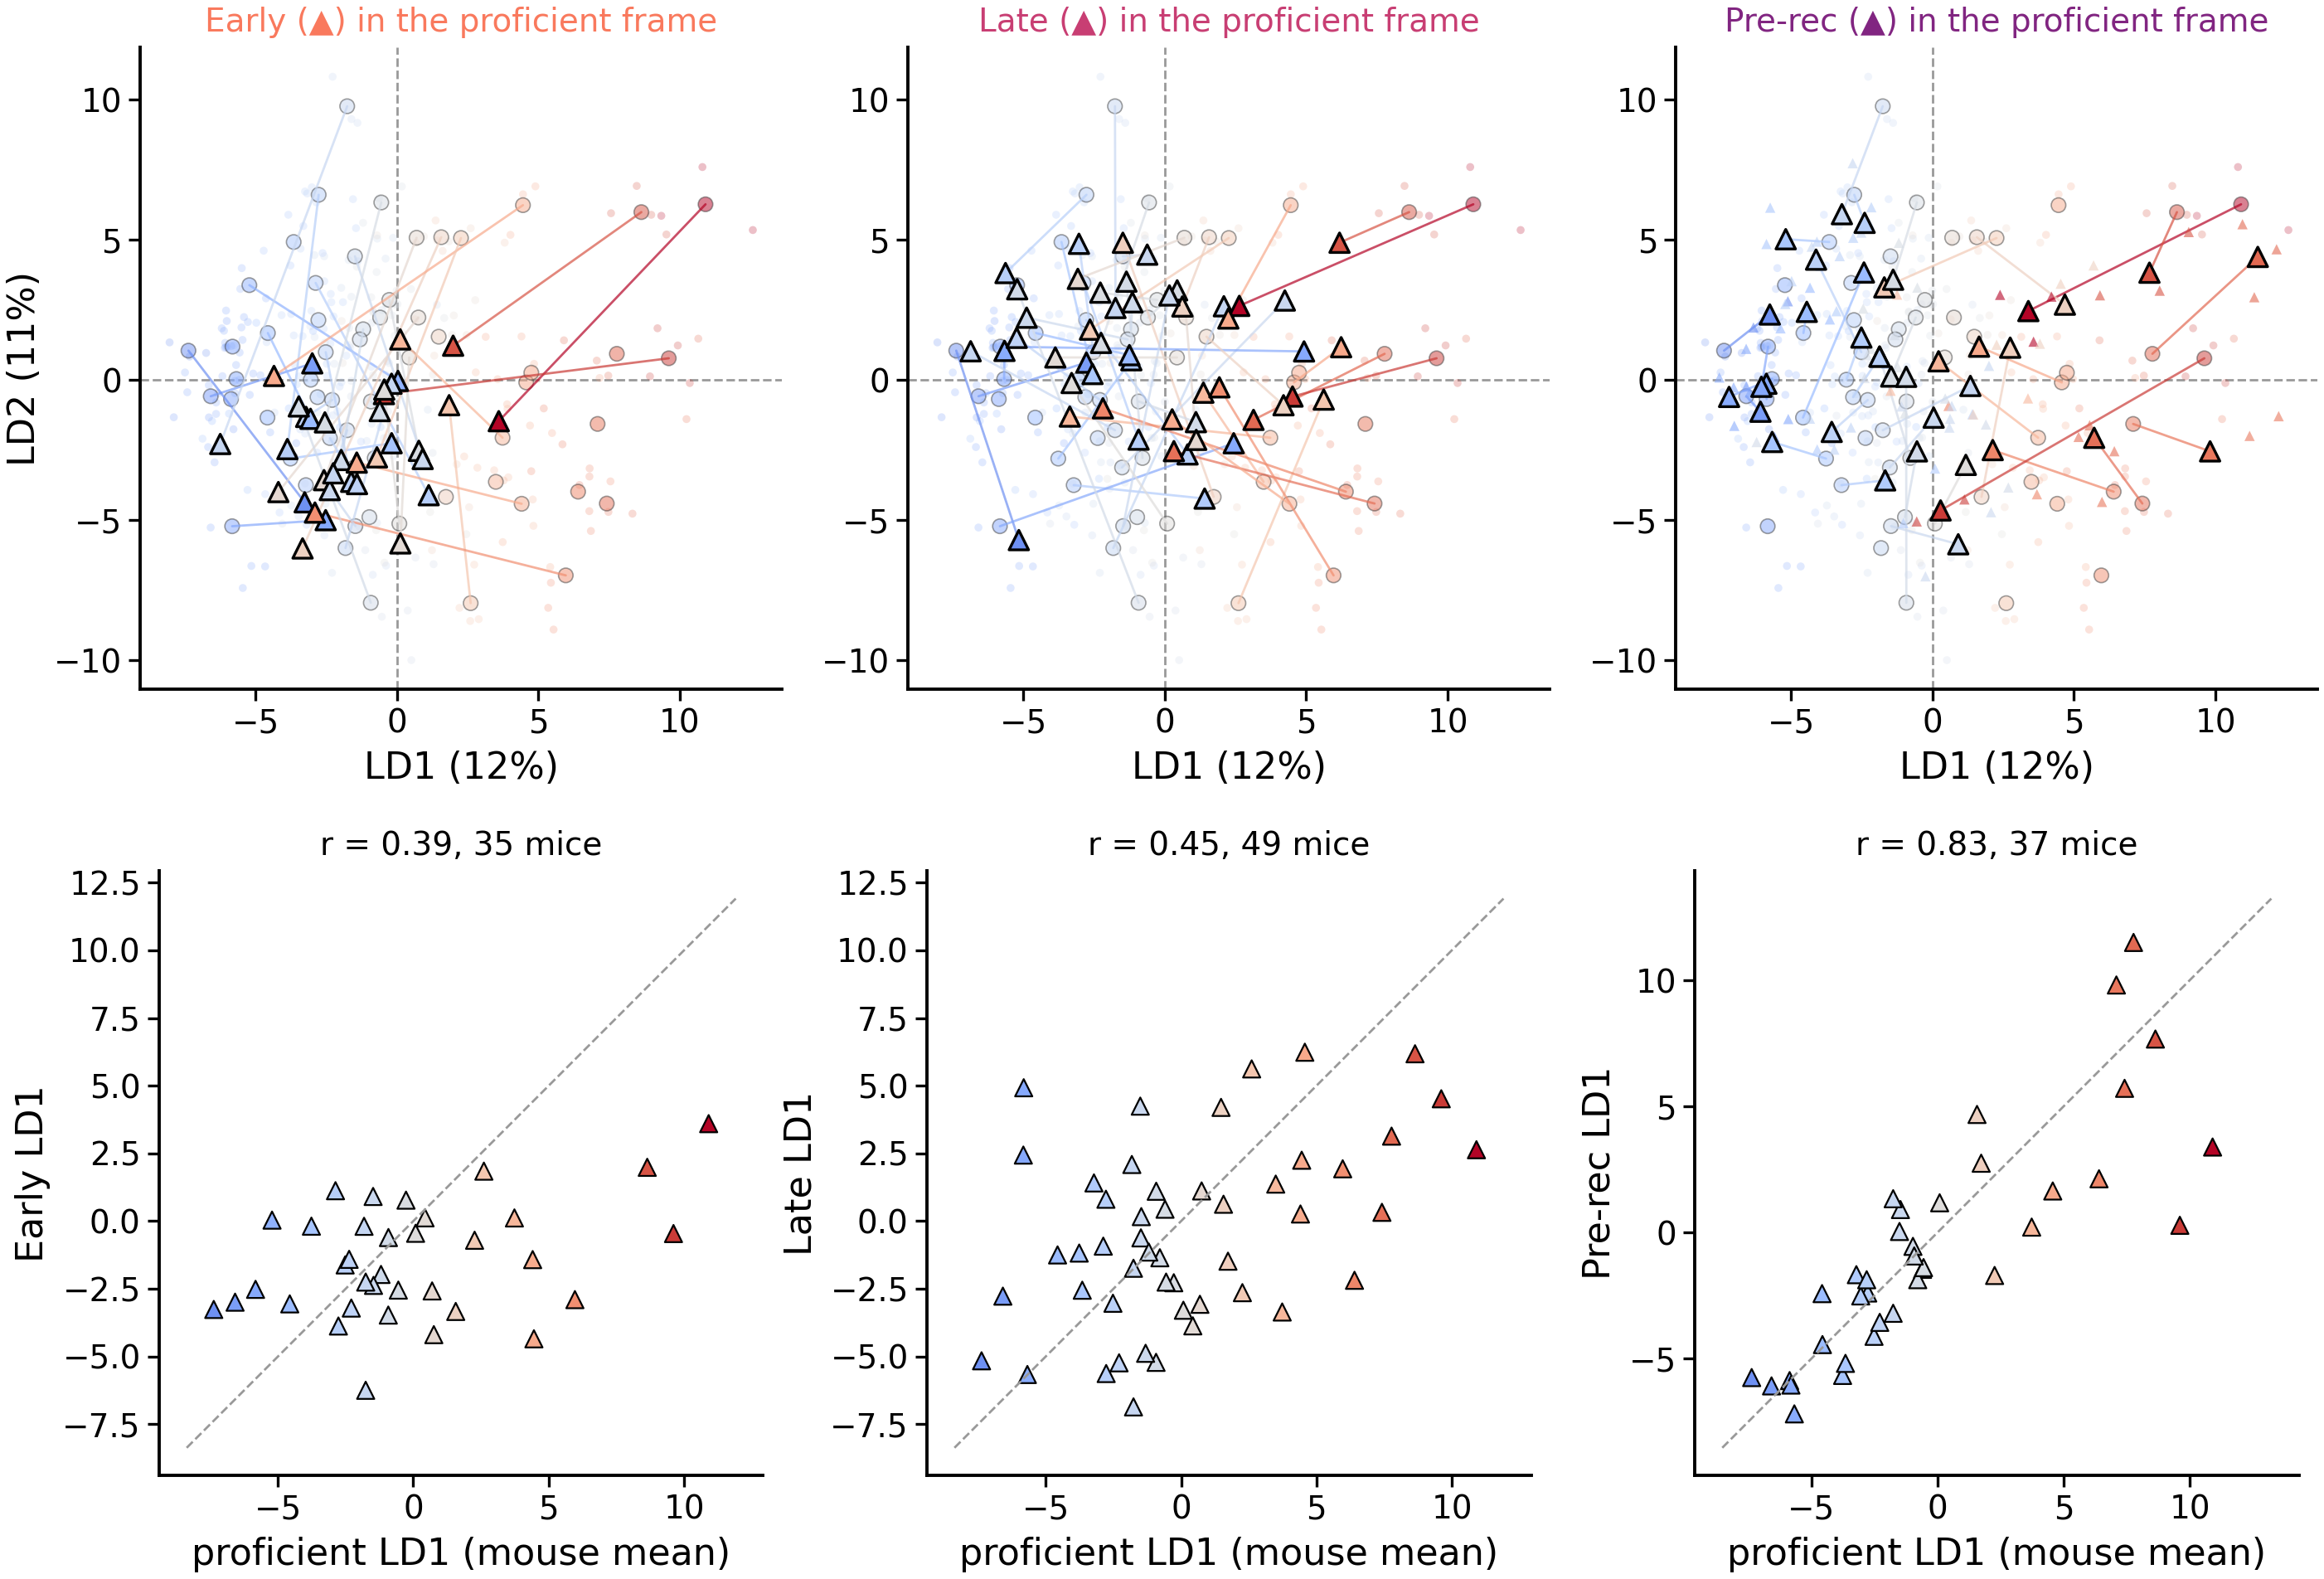

In [4]:
#%%
""" FIGURE: as fig_ld1 panel A. Proficient sessions (small) and mouse means (+/- SEM) on the LD1 gradient;
per stage, that stage's sessions and mouse means (triangles, black edge) in their mouse's proficient colour,
joined to the mouse's proficient mean. Bottom: stage vs proficient LD1, mouse means. """
lds = [c for c in sc if c.startswith('LD')]
B = sc.groupby('mouse_name')[lds].mean()
SE = sc.groupby('mouse_name')[lds].std().div(np.sqrt(sc.groupby('mouse_name').size()), axis=0)
COL = dict(zip(B.index, ps.ld1_colors(B['LD1'].to_numpy())))
x, y = 'LD1', 'LD2'
fig, axes = plt.subplots(2, 3, figsize=(7.2, 5.0), gridspec_kw=dict(height_ratios=[1.25, 1]))
for k, t in enumerate(spj.STAGES):
    ax = axes[0, k]
    ax.scatter(sc[x], sc[y], c=[COL[m] for m in sc['mouse_name']], s=3, alpha=0.25, lw=0, zorder=1)
    ax.scatter(B[x], B[y], c=[COL[m] for m in B.index], s=10, alpha=0.5, lw=0.3, edgecolor='0.25', zorder=2)
    Z = P[(P['stage'] == t) & P['mouse_name'].isin(B.index)]
    M = Z.groupby('mouse_name')[[x, y]].mean()
    for m in M.index:
        ax.plot([B.loc[m, x], M.loc[m, x]], [B.loc[m, y], M.loc[m, y]], color=COL[m], lw=0.5, alpha=0.7, zorder=2)
    ax.scatter(Z[x], Z[y], c=[COL[m] for m in Z['mouse_name']], s=5, marker='^', alpha=0.6, lw=0, zorder=3)
    ax.scatter(M[x], M[y], c=[COL[m] for m in M.index], s=18, marker='^', edgecolor='k', lw=0.6, zorder=4)
    for f in (ax.axvline, ax.axhline):
        f(0, color='0.6', ls='--', lw=0.5, zorder=0)
    ax.set_box_aspect(1)
    ax.set_title(f'{t} (▲) in the proficient frame', fontsize=7, color=ps.TIMEPOINT[t])
    ax.set_xlabel(f'LD1 ({100 * SHARE[0]:.0f}%)'); ax.set_ylabel(f'LD2 ({100 * SHARE[1]:.0f}%)' if k == 0 else '')
    ax2 = axes[1, k]
    ax2.scatter(B.loc[M.index, 'LD1'], Z.groupby('mouse_name')['LD1'].mean().reindex(M.index),
                c=[COL[m] for m in M.index], s=14, marker='^', edgecolor='k', lw=0.4)
    lim = [min(B['LD1'].min(), Z['LD1'].min()) - 1, max(B['LD1'].max(), Z['LD1'].max()) + 1]
    ax2.plot(lim, lim, color='0.6', ls='--', lw=0.5)
    ax2.set_box_aspect(1)
    ax2.set_xlabel('proficient LD1 (mouse mean)'); ax2.set_ylabel(f'{t} LD1' if True else '')
    ax2.set_title(f"r = {T.loc[t, 'r LD1']:.2f}, {T.loc[t, 'mice']} mice", fontsize=7)
plt.tight_layout()
import os; os.makedirs('figures', exist_ok=True); fig.savefig('figures/lda_stage_projection.png', dpi=300, bbox_inches='tight')
plt.show()

## Reading

- **Pre-rec (same rig, 30 Hz camera, few days)**: mice move 4.8 LD units (40 % of a typical mouse's distance from the centre),
  but only ≈ 3 % of that displacement is on LD1–3, which carry 32 % of the between-mouse variance. On those axes
  mice keep their place (r ≈ 0.83 / 0.73 / 0.73) and half the sessions still pick their own mouse out of 58.
  **The 30 Hz acquisition leaves a signature in the syllables, but in directions that are not the individuality axes.**
- **Late, Early (training rig + learning)**: larger displacements and mice keep their LD1 place less (Spearman
  ρ = 0.38, q = 0.011 / 0.22, n.s.); Late's retention does not survive removing lab (0.19, n.s.), Pre-rec's does
  (0.89 → 0.83, q < 0.001),
  own-mouse identification near chance for Early; the learning-stage change is what moves mice on LD1.
- This is also why a joint BWM + NM fit puts the datasets on its first axis: a displacement spread thinly
  over many low-variance axes is, for an LDA that whitens by the within-mouse scatter, a large between-mouse
  difference, and it gets an axis of its own.